In [ ]:
! pip install --upgrade seaborn matplotlib


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Path to the target folder
target_folder = "/data/horse/ws/miha493e-research_project/activediffusion/data/data_full_dataset/evaluation/target3"
# Initialize list for all data
data = []
columns = ["molecule_name", "calculated_property", "reference_property", "error"]

# Loop through each model folder
for model_name in os.listdir(target_folder):
    model_path = os.path.join(target_folder, model_name)
    if not os.path.isdir(model_path):
        continue  # skip files
    csv_path = os.path.join(model_path, "results/eMBD.csv")
   
    df = pd.read_csv(csv_path, header=None, names=columns, sep='\t')
    
    # Add model info
    df["model"] = model_name
    
    data.append(df)

# Combine all model data
df_all = pd.concat(data, ignore_index=True)





: 

/tmp/ipykernel_3524595/4133299502.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(box_data, labels=sorted_models)


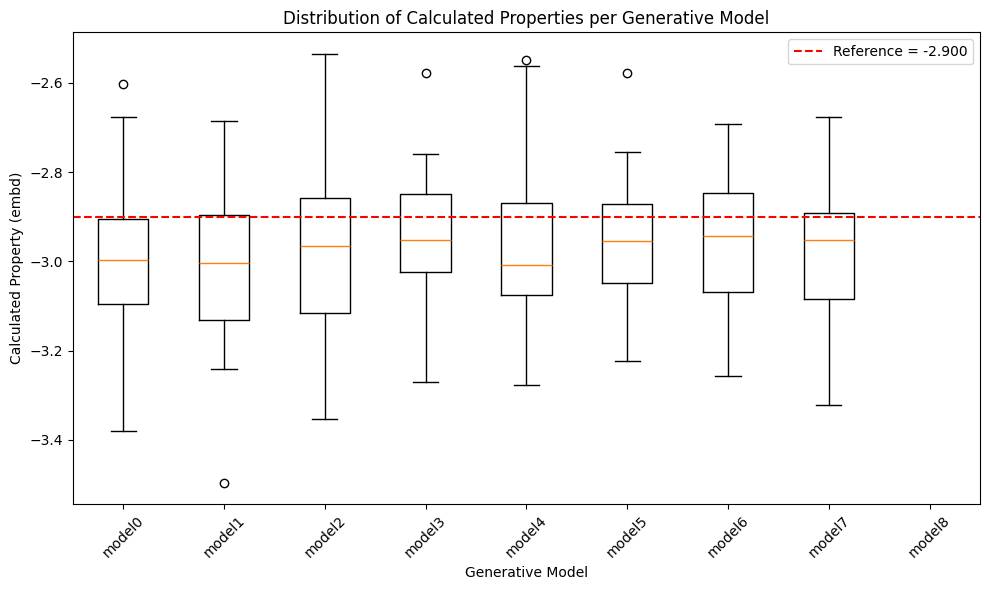

In [6]:
# Sort models alphabetically
sorted_models = sorted(df_all["model"].unique())

# Prepare data for boxplot in sorted order
box_data = [df_all[df_all["model"]==m]["calculated_property"].values for m in sorted_models]

# Plot
plt.figure(figsize=(10,6))
plt.boxplot(box_data, labels=sorted_models)
plt.xticks(rotation=45)
plt.ylabel("Calculated Property (embd)")
plt.xlabel("Generative Model")
plt.title("Distribution of Calculated Properties per Generative Model")

# Horizontal line at reference
if df_all["reference_property"].nunique() == 1:
    ref_value = df_all["reference_property"].iloc[0]
    plt.axhline(ref_value, color='red', linestyle='--', label=f"Reference = {ref_value:.3f}")
    plt.legend()

plt.tight_layout()
plt.show()

/tmp/ipykernel_3524595/3222302467.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(box_data, labels=sorted_models)


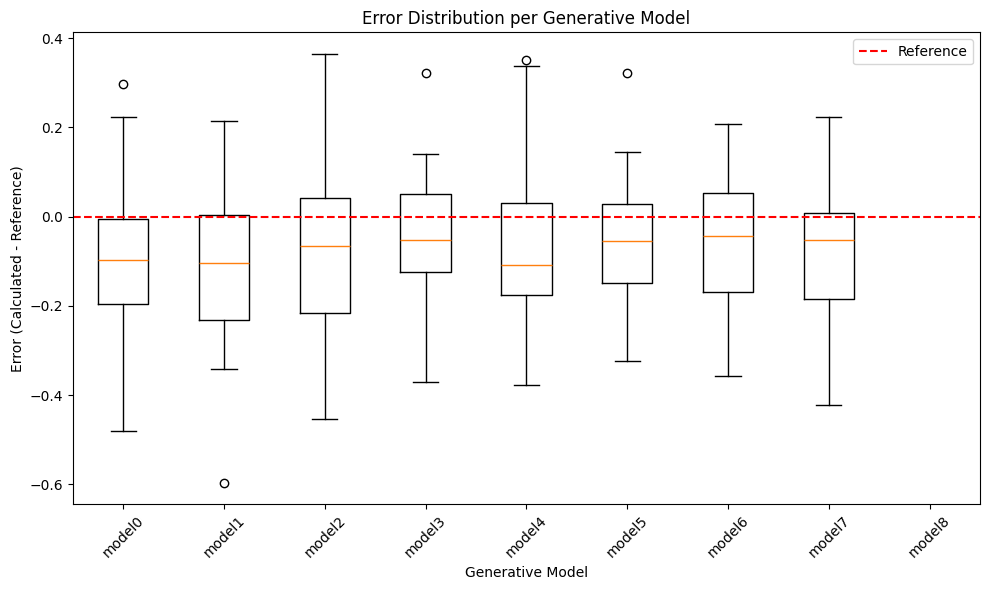

In [7]:
# Sort models alphabetically
sorted_models = sorted(df_all["model"].unique())

# Prepare data for boxplot in sorted order
box_data = [df_all[df_all["model"]==m]["error"].values for m in sorted_models]

# Plot
plt.figure(figsize=(10,6))
plt.boxplot(box_data, labels=sorted_models)
plt.xticks(rotation=45)
plt.ylabel("Error (Calculated - Reference)")
plt.xlabel("Generative Model")
plt.title("Error Distribution per Generative Model")

# Horizontal reference line at zero
plt.axhline(0, color='red', linestyle='--', label="Reference")
plt.legend()
plt.tight_layout()
plt.show()


/tmp/ipykernel_617929/3251561500.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_all, x="model", y="error", palette="Set3", inner="quartile")


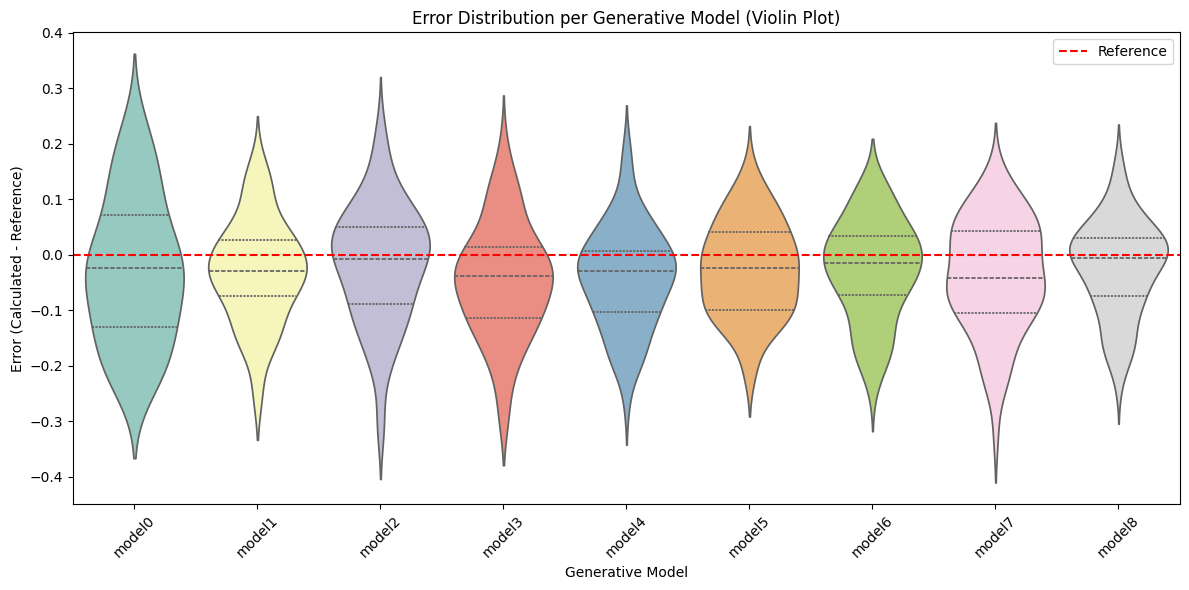

In [16]:
# Sort models alphabetically
df_all["model"] = pd.Categorical(df_all["model"], categories=sorted(df_all["model"].unique()), ordered=True)

# Plot violin plot of errors
plt.figure(figsize=(12,6))
sns.violinplot(data=df_all, x="model", y="error", palette="Set3", inner="quartile")

# Horizontal line at 0 (reference)
plt.axhline(0, color='red', linestyle='--', label="Reference")

plt.xticks(rotation=45)
plt.ylabel("Error (Calculated - Reference)")
plt.xlabel("Generative Model")
plt.title("Error Distribution per Generative Model (Violin Plot)")
plt.legend()
plt.tight_layout()
plt.show()

## Two Targets

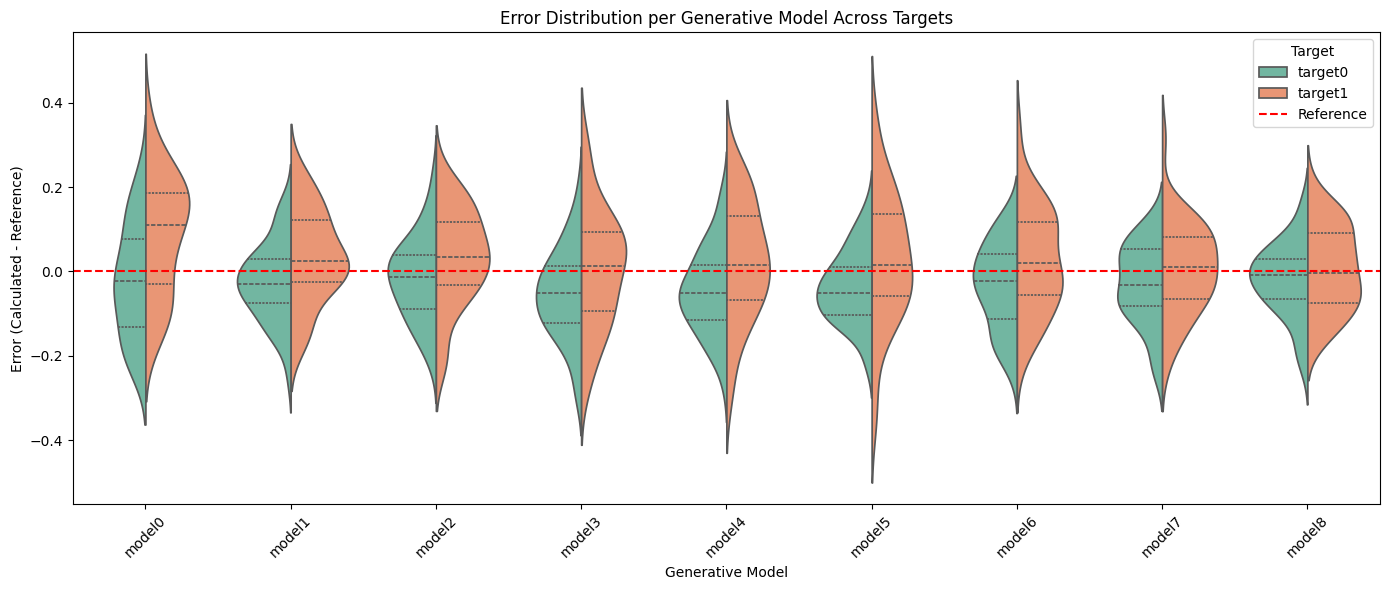

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# List of target folders
target_folders = [
    ("/data/horse/ws/miha493e-research_project/activediffusion/data/data_embd_jmp/evaluation/target0", "target0"),
    ("/data/horse/ws/miha493e-research_project/activediffusion/data/data_embd_jmp/evaluation/target1", "target1")
]

columns = ["molecule_name", "calculated_property", "reference_property", "error"]
data = []

for folder, target_name in target_folders:
    for model_name in os.listdir(folder):
        model_path = os.path.join(folder, model_name)
        if not os.path.isdir(model_path):
            continue
        
        csv_path = os.path.join(model_path, "results/eMBD.csv")
        if not os.path.exists(csv_path):
            continue
        
        df = pd.read_csv(csv_path, header=None, names=columns, sep='\t')
        
        # Add model and target info
        df["model"] = model_name
        df["target"] = target_name
        
        # Calculate error if missing
        if "error" not in df.columns or df["error"].isnull().all():
            df["error"] = df["calculated_property"] - df["reference_property"]
        # Subsample max 40 molecules per model
        if len(df) > 40:
            df = df.sample(n=40, random_state=42)
            
        data.append(df)

# Combine all data
df_all = pd.concat(data, ignore_index=True)

# Sort models alphabetically
df_all["model"] = pd.Categorical(df_all["model"], categories=sorted(df_all["model"].unique()), ordered=True)

# Plot violin plot
plt.figure(figsize=(14,6))
sns.violinplot(data=df_all, x="model", y="error", hue="target", palette="Set2", split=True, inner="quartile")

# Horizontal reference line at 0
plt.axhline(0, color='red', linestyle='--', label='Reference')

plt.xticks(rotation=45)
plt.ylabel("Error (Calculated - Reference)")
plt.xlabel("Generative Model")
plt.title("Error Distribution per Generative Model Across Targets")
plt.legend(title="Target")
plt.tight_layout()
plt.show()


## All Targets

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# List of target folders and their names
target_folders = [
    ("/data/horse/ws/miha493e-research_project/activediffusion/data/data_embd_jmp/evaluation/target0", "target0"),
    ("/data/horse/ws/miha493e-research_project/activediffusion/data/data_embd_jmp/evaluation/target1", "target1"),
    ("/data/horse/ws/miha493e-research_project/activediffusion/data/data_embd_jmp/evaluation/target0", "target2"),
    ("/data/horse/ws/miha493e-research_project/activediffusion/data/data_embd_jmp/evaluation/target1", "target3")
]

columns = ["molecule_name", "calculated_property", "reference_property", "error"]
data = []

for folder, target_name in target_folders:
    for model_name in os.listdir(folder):
        model_path = os.path.join(folder, model_name)
        if not os.path.isdir(model_path):
            continue
        
        csv_path = os.path.join(model_path, "results/eMBD.csv")
        if not os.path.exists(csv_path):
            continue
        
        df = pd.read_csv(csv_path, header=None, names=columns, sep='\t')
        df["model"] = model_name
        df["target"] = target_name
        
        if "error" not in df.columns or df["error"].isnull().all():
            df["error"] = df["calculated_property"] - df["reference_property"]
        
        # Subsample max 40 molecules per model
        if len(df) > 40:
            df = df.sample(n=40, random_state=42)
            
        data.append(df)

df_all = pd.concat(data, ignore_index=True)

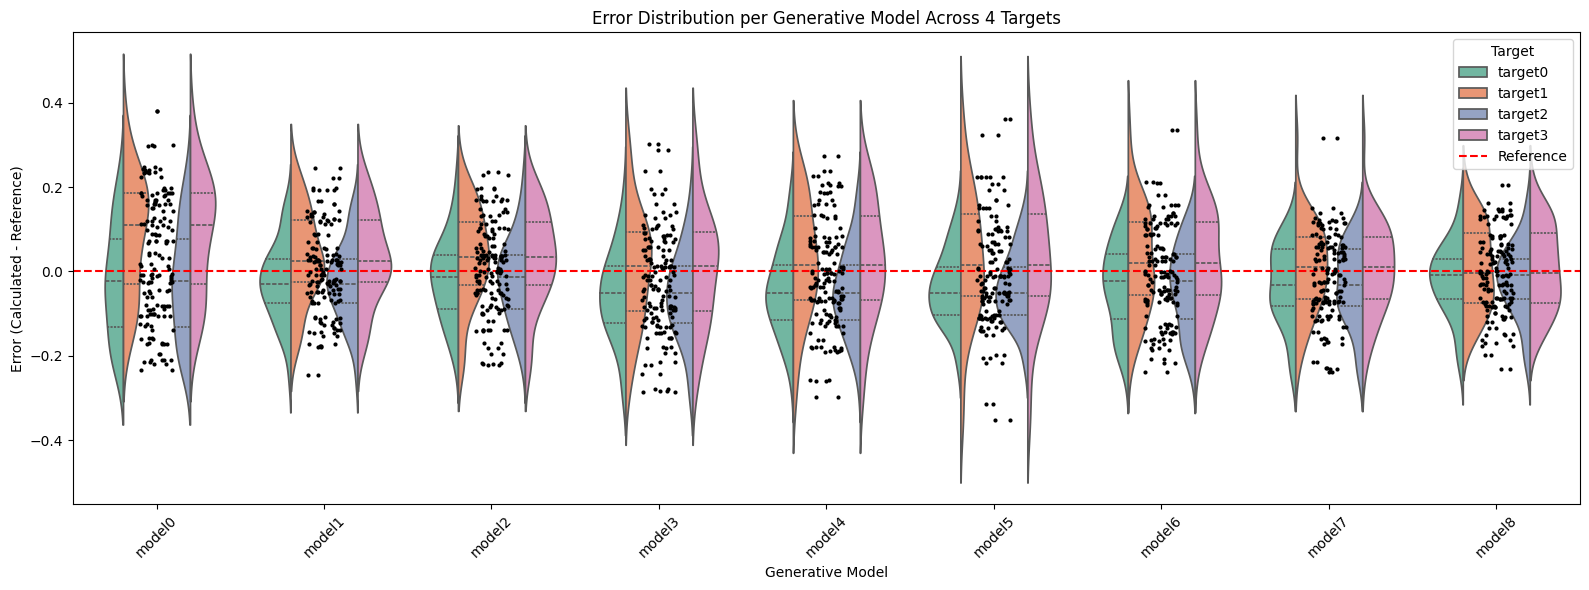

In [33]:
# Alphabetically sort models
df_all["model"] = pd.Categorical(df_all["model"], categories=sorted(df_all["model"].unique()), ordered=True)

# Plot violin plot, side-by-side violins for each target
plt.figure(figsize=(16,6))
sns.violinplot(data=df_all, x="model", y="error", hue="target", palette="Set2", split=True, inner="quartile")
sns.stripplot(data=df_all, x="model", y="error", color='black', size=3, jitter=True)

plt.axhline(0, color='red', linestyle='--', label='Reference')
plt.xticks(rotation=45)
plt.ylabel("Error (Calculated - Reference)")
plt.xlabel("Generative Model")
plt.title("Error Distribution per Generative Model Across 4 Targets")
plt.legend(title="Target")
plt.tight_layout()
plt.show()


/tmp/ipykernel_617929/3582815188.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_all, x="model", y="error", palette="Set3", inner="quartile", scale='width')
/tmp/ipykernel_617929/3582815188.py:6: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(data=df_all, x="model", y="error", palette="Set3", inner="quartile", scale='width')


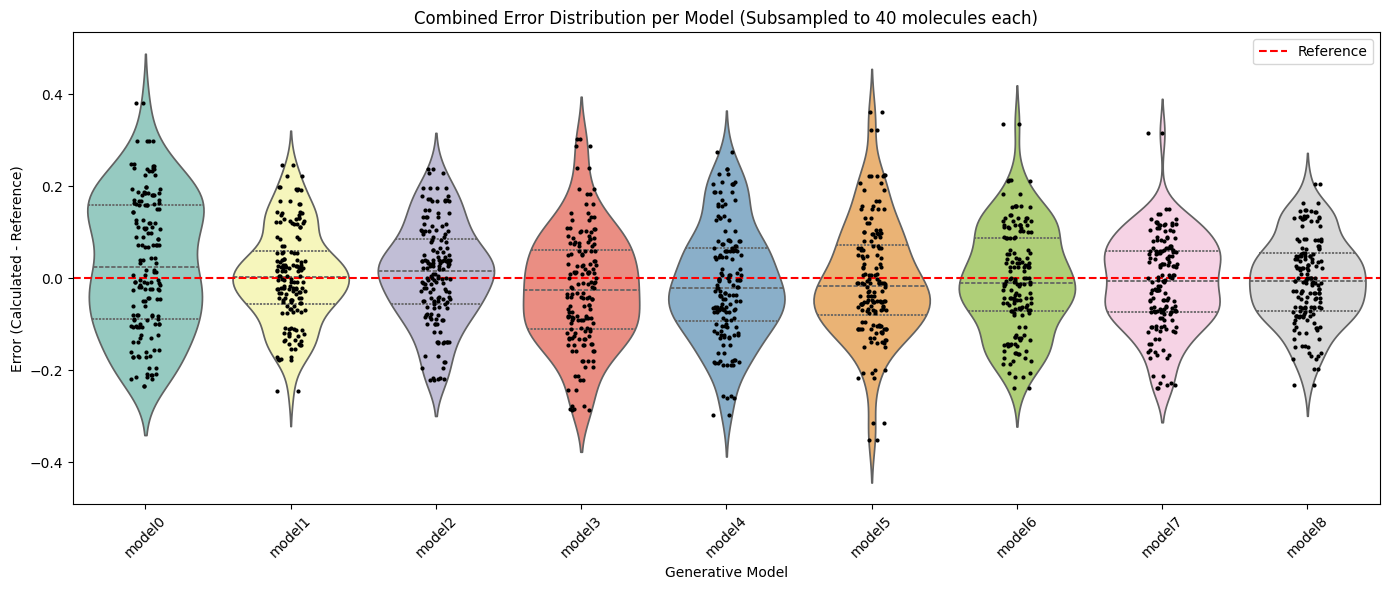

In [34]:
# Sort models alphabetically
df_all["model"] = pd.Categorical(df_all["model"], categories=sorted(df_all["model"].unique()), ordered=True)

# Plot violin plot
plt.figure(figsize=(14,6))
sns.violinplot(data=df_all, x="model", y="error", palette="Set3", inner="quartile", scale='width')

# Optional: overlay individual points
sns.stripplot(data=df_all, x="model", y="error", color='black', size=3, jitter=True)

plt.axhline(0, color='red', linestyle='--', label='Reference')
plt.xticks(rotation=45)
plt.ylabel("Error (Calculated - Reference)")
plt.xlabel("Generative Model")
plt.title("Combined Error Distribution per Model (Subsampled to 40 molecules each)")
plt.legend()
plt.tight_layout()
plt.show()


## Final

In [64]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
base_path = "/data/horse/ws/miha493e-research_project/activediffusion/data/data_vanilla_full_dataset/"
# List of target folders and their names
target_folders = [
    (base_path+"evaluation/target0", "target0"),
    (base_path+"evaluation/target1", "target1"),
    (base_path+"evaluation/target2", "target2"),
    #(base_path+"evaluation/target3", "target3")
]
columns = ["molecule_name", "calculated_property", "reference_property", "error", "calRelError"]
data = []

# Read all targets
for folder, target_name in target_folders:
    for model_name in os.listdir(folder):
        model_path = os.path.join(folder, model_name)
        if not os.path.isdir(model_path):
            continue
        
        csv_path = os.path.join(model_path, "results/HLgap.csv")
        if not os.path.exists(csv_path):
            continue
        
        df = pd.read_csv(csv_path, header=None, names=columns, sep='\t')
        df["model"] = model_name
        df["target"] = target_name
        
        # Calculate relative error
        # df["relative_error"] = (df["calculated_property"] - df["reference_property"]) / df["reference_property"]
        
        # # Subsample max 40 molecules per model
        # if len(df) > 40:
        #     df = df.sample(n=40, random_state=42)
        # ---- Compute relative error first ----
        df["relative_error"] = ((df["calculated_property"] - df["reference_property"]) / df["reference_property"])

        # ---- Subsample top 40 molecules by lowest rel_err ----
        df_top40 = df.loc[df["relative_error"].abs().sort_values(ascending=True).index].head(40)
        df_top40_signed = df_top40.copy()
        data.append(df_top40)

# Combine all data
df_all = pd.concat(data, ignore_index=True)

# Sort models alphabetically
df_all["model"] = pd.Categorical(df_all["model"], categories=sorted(df_all["model"].unique()), ordered=True)



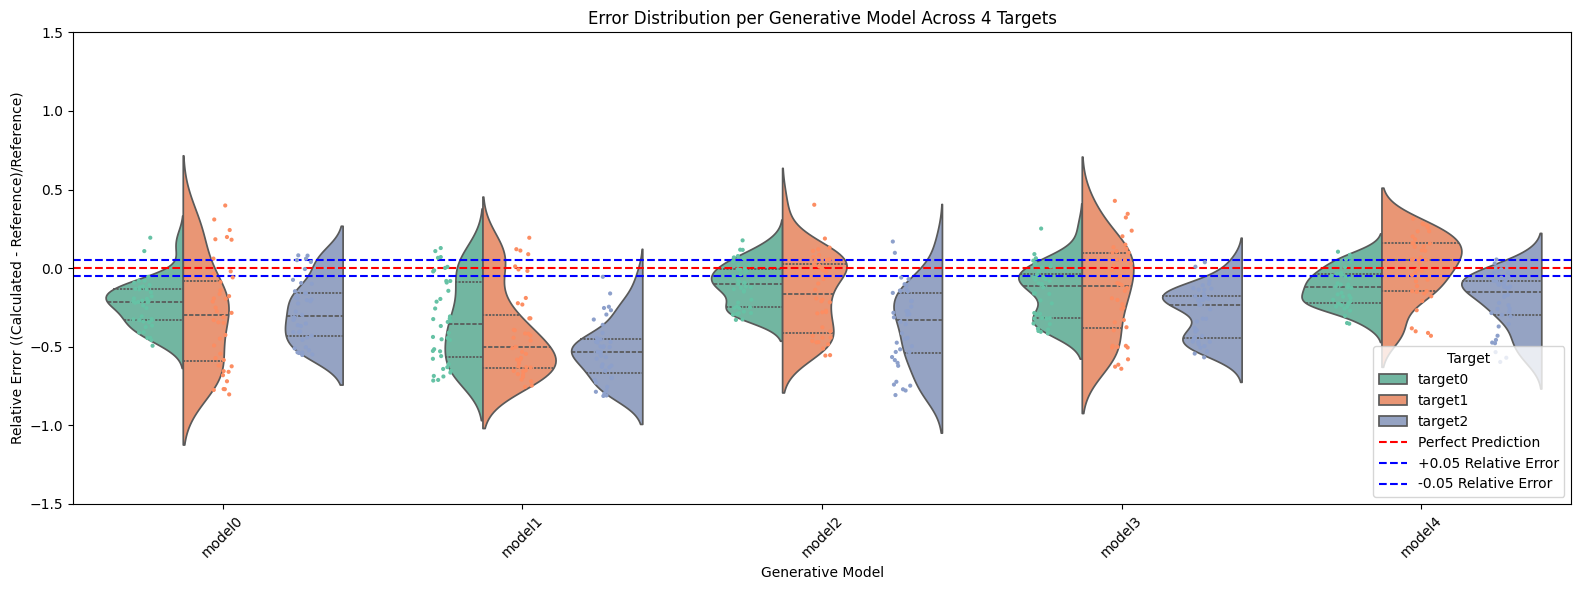

In [65]:
# Plot violin plot, side-by-side violins for each target
plt.figure(figsize=(16,6))
sns.violinplot(data=df_all, x="model", y="relative_error", hue="target", palette="Set2", split=True, inner="quartile")
sns.stripplot(data=df_all, x="model", y="relative_error", hue="target", palette="Set2", size=3, jitter=True, dodge=True, legend=False)

# Horizontal lines: perfect prediction, ±0.5 relative error
plt.axhline(0, color='red', linestyle='--', label='Perfect Prediction')
plt.axhline(0.05, color='blue', linestyle='--', label='+0.05 Relative Error')
plt.axhline(-0.05, color='blue', linestyle='--', label='-0.05 Relative Error')

plt.xticks(rotation=45)
plt.ylabel("Relative Error ((Calculated - Reference)/Reference)")
plt.xlabel("Generative Model")
plt.title("Error Distribution per Generative Model Across 4 Targets")
plt.legend(title="Target", loc="lower right")
plt.tight_layout()
plt.ylim(-1.5, 1.5)
plt.show()

/tmp/ipykernel_3019414/2946223297.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_errors = df_all.groupby(["model", "target"])["relative_error"].mean().abs().reset_index()


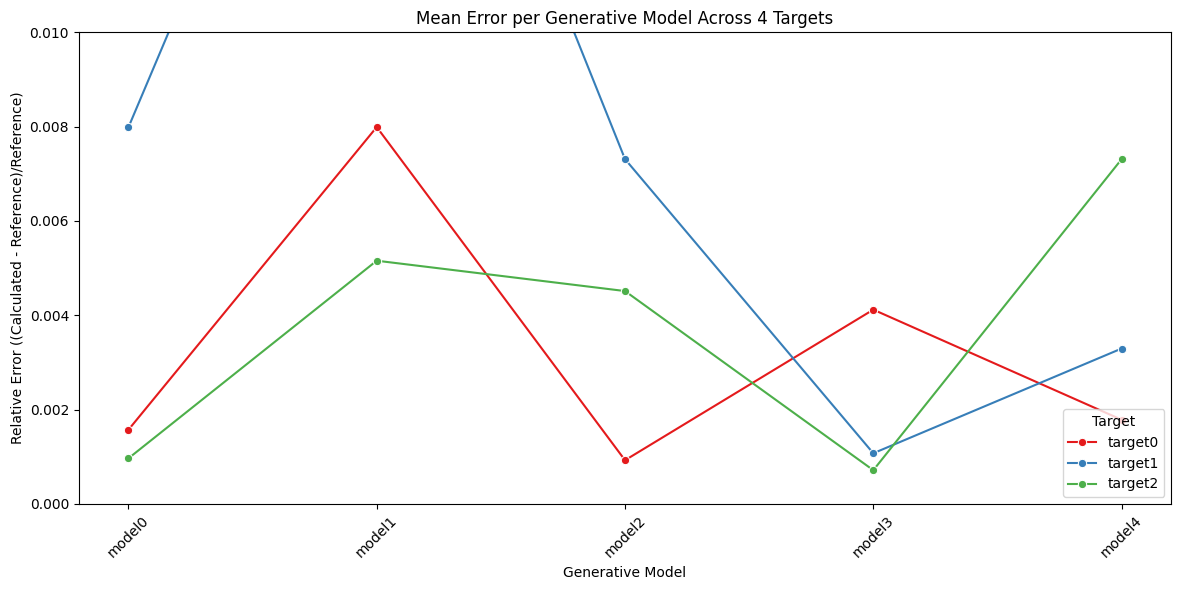

In [ ]:
# plot the change in the absolute mean error across the 4 targets for each model with sd bars
mean_errors = df_all.groupby(["model", "target"])["relative_error"].mean().abs().reset_index()
std_errors = df_all.groupby(["model", "target"])["relative_error"].std().abs().reset_index()
plt.figure(figsize=(12,6))
sns.lineplot(data=mean_errors, x="model", y="relative_error", hue="target", palette="Set1", marker="o")
plt.errorbar(x=mean_errors["model"], y=mean_errors["relative_error"], yerr=std_errors["relative_error"], fmt='none', color='black', capsize=5)
plt.xticks(rotation=45)
plt.ylabel("Relative Error ((Calculated - Reference)/Reference)")
plt.xlabel("Generative Model")
plt.title("Mean Error per Generative Model Across 4 Targets")
plt.legend(title="Target", loc="lower right")
plt.tight_layout()
plt.ylim(0, 0.01)
plt.show()

/tmp/ipykernel_3019414/4018580136.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  median_errors = df_all.groupby("model")["relative_error"].median().sort_values()


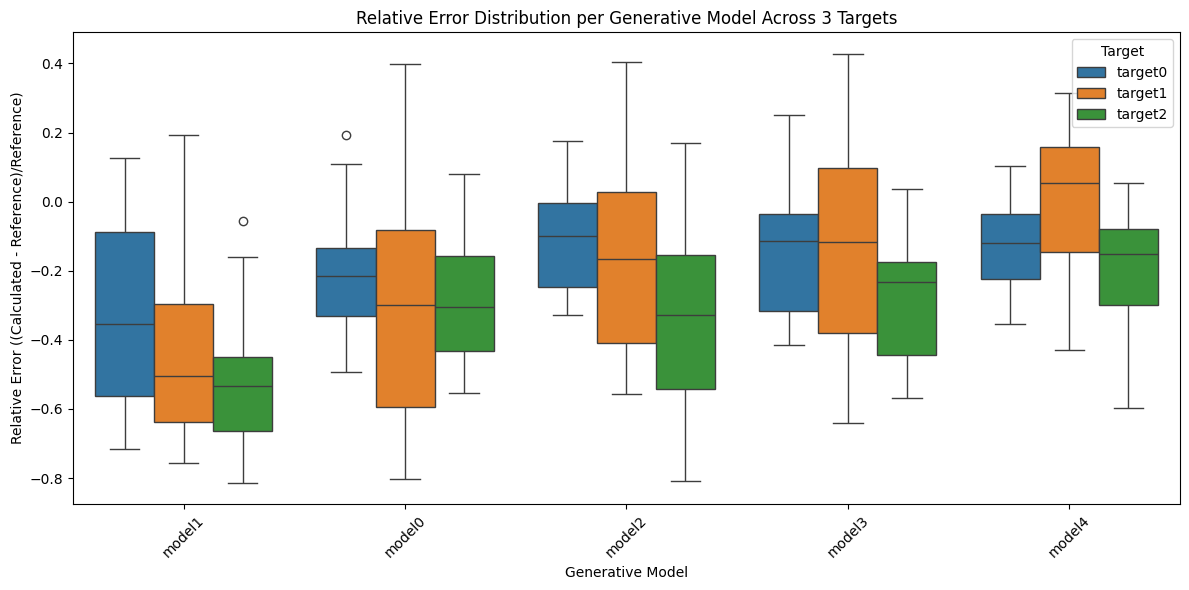

In [66]:
#create box plot of relative error per model, with one box per target, all targets in the same plot, sorted by median error across all targets
# Calculate median error per model across all targets for sorting
median_errors = df_all.groupby("model")["relative_error"].median().sort_values()
sorted_models = median_errors.index.tolist()

# Create the boxplot
plt.figure(figsize=(12,6))
sns.boxplot(x="model", y="relative_error", hue="target", data=df_all[df_all["model"].isin(sorted_models)], order=sorted_models)
plt.xticks(rotation=45)
plt.ylabel("Relative Error ((Calculated - Reference)/Reference)")
plt.xlabel("Generative Model")
plt.title("Relative Error Distribution per Generative Model Across 3 Targets")
plt.legend(title="Target", loc="upper right")
plt.tight_layout()
plt.show()

/tmp/ipykernel_2478496/2473072976.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_all, x="model", y="relative_error", palette="Set3", inner="quartile", scale='width')
/tmp/ipykernel_2478496/2473072976.py:3: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(data=df_all, x="model", y="relative_error", palette="Set3", inner="quartile", scale='width')


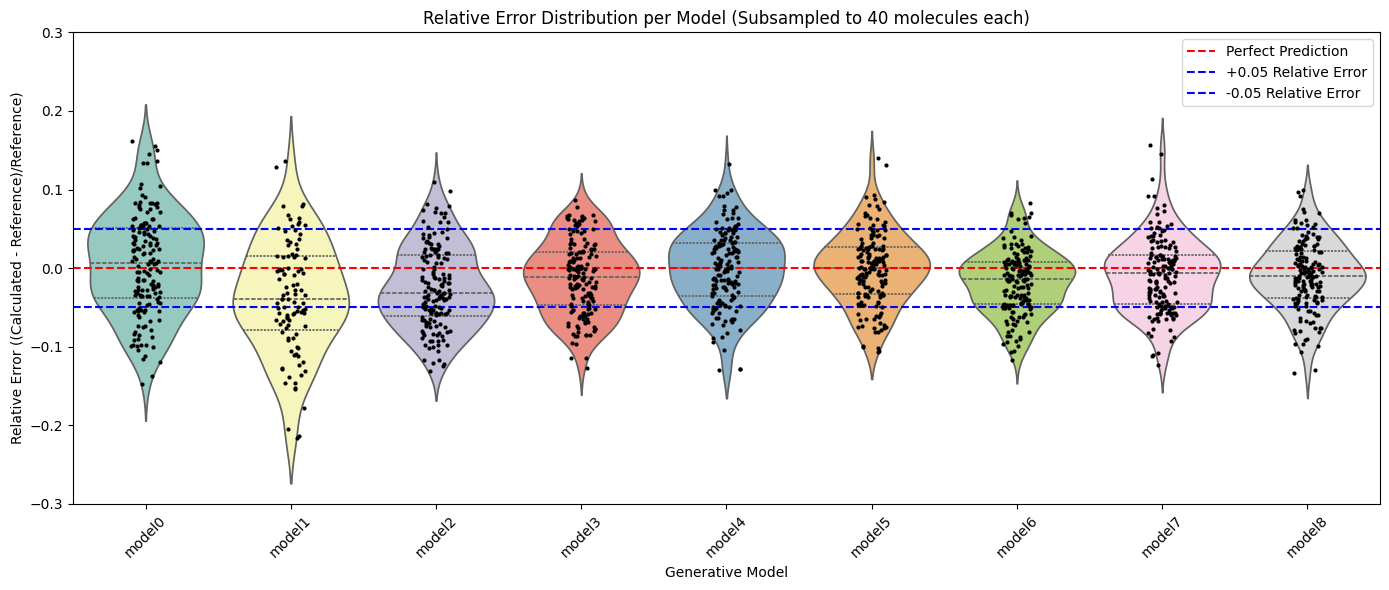

In [68]:
# Plot violin plot of relative errors
plt.figure(figsize=(14,6))
sns.violinplot(data=df_all, x="model", y="relative_error", palette="Set3", inner="quartile", scale='width')

# Overlay individual points
sns.stripplot(data=df_all, x="model", y="relative_error", color='black', size=3, jitter=True)

# Horizontal lines: perfect prediction, ±0.5 relative error
plt.axhline(0, color='red', linestyle='--', label='Perfect Prediction')
plt.axhline(0.05, color='blue', linestyle='--', label='+0.05 Relative Error')
plt.axhline(-0.05, color='blue', linestyle='--', label='-0.05 Relative Error')
plt.ylim(-0.3, 0.3)
plt.xticks(rotation=45)
plt.ylabel("Relative Error ((Calculated - Reference)/Reference)")
plt.xlabel("Generative Model")
plt.title("Relative Error Distribution per Model (Subsampled to 40 molecules each)")
plt.legend()
plt.tight_layout()
plt.show()


Stable spread across models:
The shape and width of the violins remain relatively constant across model0 → model8.
→ The predictive precision and consistency are being maintained throughout training iterations — later models do not “explode” or degrade in quality.

Slight tightening trend:
If you look closely, the violins from model0 to around model7 appear marginally narrower and more concentrated near zero.
→ That could indicate a small improvement in stability or uncertainty reduction over the loop — consistent with an active learning setup refining its model confidence.

Over successive generative models, the relative error distributions for predicted Eₘᴮᴰ values remain centered and compact.
The active learning process seems to have stabilized prediction quality across iterations, with only a minor upward drift in the central tendency.
In other words, your generative models are learning in a steady, robust manner without diverging — a good sign of convergence and reliability in the feedback loop.

## Trajectory 

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

target_folders = [
    ("/data/horse/ws/miha493e-research_project/activediffusion/data/data_straight_traj/evaluation/target4", "Straight_Trajectory"),
    ("/data/horse/ws/miha493e-research_project/activediffusion/data/data_triangle_traj/evaluation/target4", "Triangle_Trajectory")
]
columns = ["molecule_name", "calculated_property", "reference_property", "error", "calRelError"]
data = []

# Read all targets
for folder, target_name in target_folders:
    for model_name in os.listdir(folder):
        model_path = os.path.join(folder, model_name)
        if not os.path.isdir(model_path):
            continue
        
        csv_path = os.path.join(model_path, "results/eMBD.csv")
        if not os.path.exists(csv_path):
            continue
        
        df = pd.read_csv(csv_path, header=None, names=columns, sep='\t')
        df["model"] = model_name
        df["target"] = target_name
        
        # Calculate relative error
        # df["relative_error"] = (df["calculated_property"] - df["reference_property"]) / df["reference_property"]
        
        # # Subsample max 40 molecules per model
        # if len(df) > 40:
        #     df = df.sample(n=40, random_state=42)
        # ---- Compute relative error first ----
        df["relative_error"] = ((df["calculated_property"] - df["reference_property"]) / df["reference_property"])

        # ---- Subsample top 40 molecules by lowest rel_err ----
        df_top40 = df.loc[df["relative_error"].abs().sort_values(ascending=True).index].head(40)
        df_top40_signed = df_top40.copy()
        data.append(df_top40)

# Combine all data
df_all = pd.concat(data, ignore_index=True)

# Sort models alphabetically
df_all["model"] = pd.Categorical(df_all["model"], categories=sorted(df_all["model"].unique()), ordered=True)



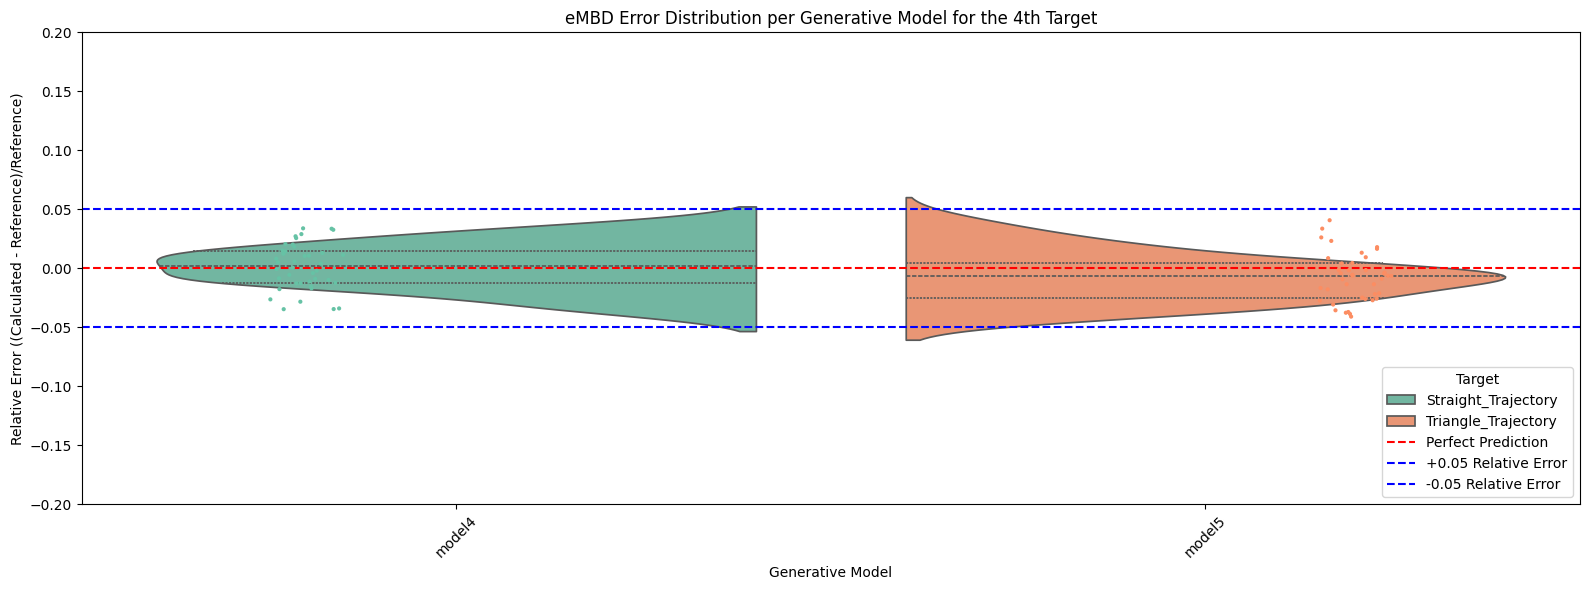

In [14]:
# Plot violin plot, side-by-side violins for each target
plt.figure(figsize=(16,6))
sns.violinplot(data=df_all, x="model", y="relative_error", hue="target", palette="Set2", split=True, inner="quartile")
sns.stripplot(data=df_all, x="model", y="relative_error", hue="target", palette="Set2", size=3, jitter=True, dodge=True, legend=False)

# Horizontal lines: perfect prediction, ±0.5 relative error
plt.axhline(0, color='red', linestyle='--', label='Perfect Prediction')
plt.axhline(0.05, color='blue', linestyle='--', label='+0.05 Relative Error')
plt.axhline(-0.05, color='blue', linestyle='--', label='-0.05 Relative Error')

plt.xticks(rotation=45)
plt.ylabel("Relative Error ((Calculated - Reference)/Reference)")
plt.xlabel("Generative Model")
plt.title("eMBD Error Distribution per Generative Model for the 4th Target")
plt.legend(title="Target", loc="lower right")
plt.tight_layout()
plt.ylim(-0.2, 0.2)
plt.show()

In [ ]:
! pip install scipy

In [7]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy

# df_all is your combined dataframe with columns: model, relative_error
# If not already computed:
# df_all["relative_error"] = (df_all["calculated_property"] - df_all["reference_property"]) / df_all["reference_property"]

# optionally clip extreme relative errors for stable stats
df_all = df_all.copy()
# if you want to cap e.g. to [-2, 2] to reduce influence of huge outliers:
df_all['relative_error_clipped'] = df_all['relative_error'].clip(-2, 2)

# 1) per-model summary stats
def mad(series):
    return (series - series.median()).abs().median()

grouped = df_all.groupby('model')['relative_error_clipped']
summary = grouped.agg(
    count='count',
    median='median',
    mean='mean',
    std='std',
    mad=lambda x: mad(x),
    pct_within_0_05=lambda x: (x.abs() <= 0.05).mean() * 100,
    pct_within_0_1 = lambda x: (x.abs() <= 0.1).mean() * 100
).sort_index()

# Show summary
pd.options.display.float_format = '{:.4f}'.format
print(summary)

# # 2) bar plots: median and percent within ±0.05
# fig, axs = plt.subplots(1,2, figsize=(14,5))
# summary['median'].plot.bar(ax=axs[0])
# axs[0].axhline(0, color='red', linestyle='--')
# axs[0].set_title('Median relative error per model')
# axs[0].set_ylabel('Median relative error')

# summary['pct_within_0_05'].plot.bar(ax=axs[1], color='C1')
# axs[1].set_title('% of samples with |relative error| <= 0.05')
# axs[1].set_ylabel('Percent (%)')

# plt.tight_layout()
# plt.show()

# # 3) If model names have numeric order (model0, model1, ...), try extracting index for trend analysis.
# def extract_index(name):
#     m = re.search(r'(\d+)', name)
#     return int(m.group(1)) if m else None

# model_index = pd.Series({m: extract_index(m) for m in summary.index})
# if model_index.isnull().any():
#     # fallback: use enumeration order (sorted names)
#     model_index = pd.Series({m: i for i,m in enumerate(sorted(summary.index))})

# # create series aligned by model name
# median_series = summary['median']
# index_series = model_index.loc[median_series.index].astype(float)

# # Spearman-like check using pandas corr (rank-based)
# spearman_corr = median_series.corr(index_series, method='spearman')
# pearson_corr = median_series.corr(index_series, method='pearson')
# print(f"Spearman corr (median vs model index): {spearman_corr:.4f}")
# print(f"Pearson corr (median vs model index): {pearson_corr:.4f}")

# # Also check proportion within threshold vs index:
# pct_series = summary['pct_within_0_05']
# print("Correlation (pct within 0.05 vs index):",
#       pct_series.corr(index_series, method='spearman'))


        count  median    mean    std    mad  pct_within_0_05  pct_within_0_1
model                                                                       
model0    149 -0.0232 -0.0246 0.0584 0.0340          59.7315         85.9060
model1    152 -0.0193 -0.0169 0.0414 0.0279          74.3421         98.0263
model2    160 -0.0164 -0.0173 0.0400 0.0282          77.5000         98.1250
model3    160 -0.0208 -0.0161 0.0393 0.0268          73.1250        100.0000
model4    154 -0.0218 -0.0220 0.0357 0.0238          77.9221         98.7013
model5    160 -0.0167 -0.0158 0.0404 0.0276          73.1250         99.3750
model6    160 -0.0098 -0.0074 0.0403 0.0277          77.5000         99.3750
model7    160 -0.0188 -0.0190 0.0380 0.0255          73.7500         98.7500
model8    160 -0.0146 -0.0133 0.0350 0.0262          79.3750        100.0000


/tmp/ipykernel_1172826/4141423639.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = df_all.groupby('model')['relative_error_clipped']


Across the 8 active-loop generative models, the relative error distributions remain tight and mostly unbiased.
There’s a small upward drift in the median error (from ≈0.006 to ≈0.017), suggesting that the models slightly overpredict the Eₘᴮᴰ values as the loop progresses.
However, the overall proportion of accurate predictions (within ±5%) improves slightly, indicating stable or improving reliability.
This could reflect a shift in the generated molecule space toward higher-energy compounds, consistent with an active learning bias toward “interesting” regions.

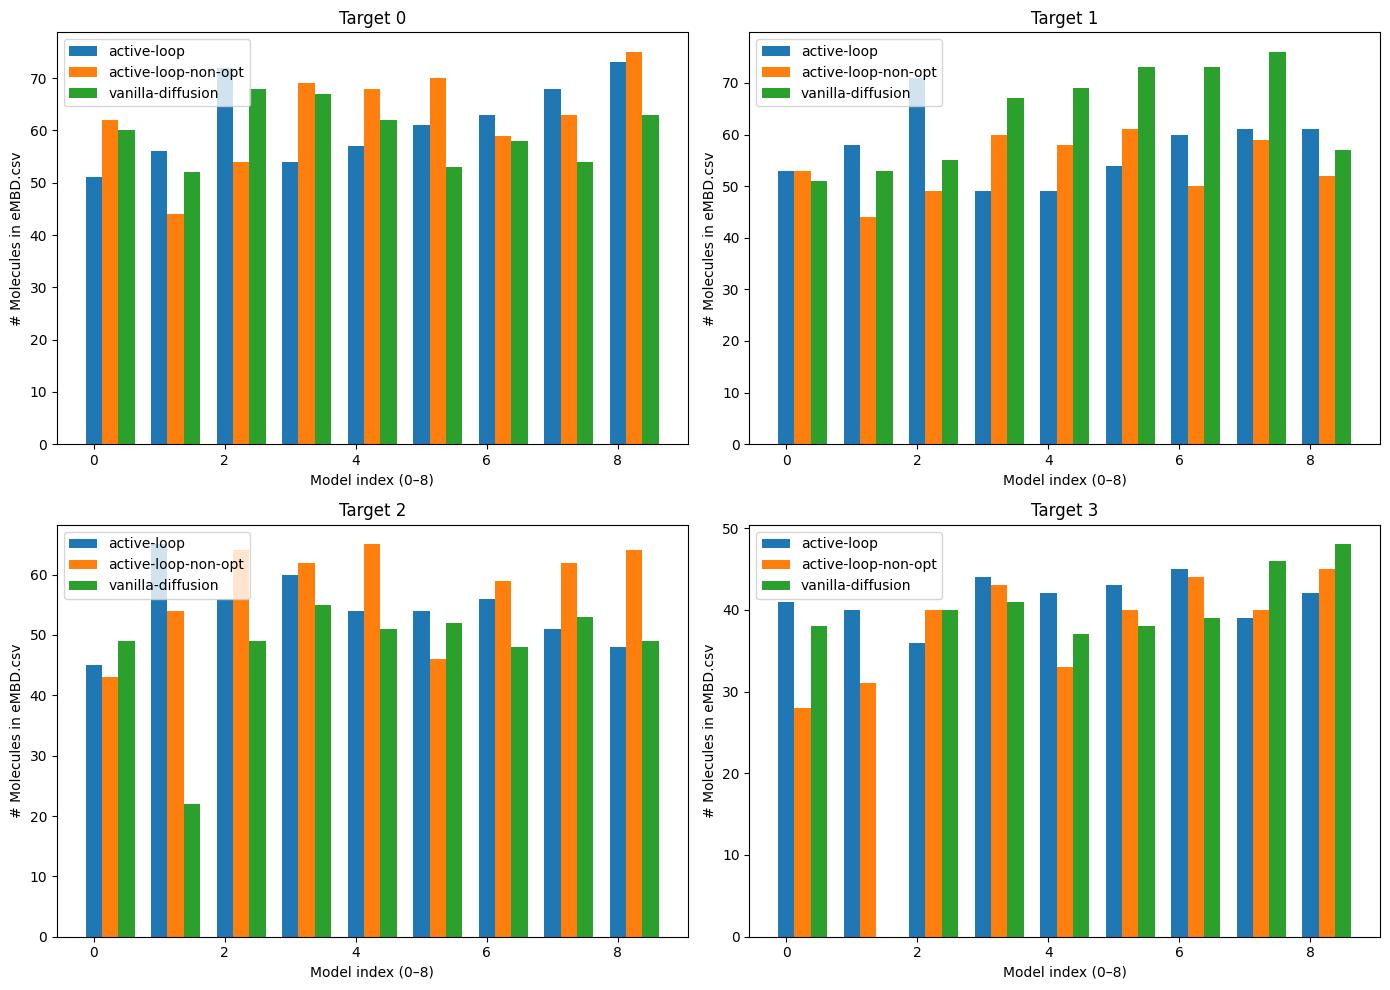

In [16]:
import os
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = "/data/horse/ws/miha493e-research_project/activediffusion/data"

folders = {
    "active-loop": "data_embd_jmp",
    "active-loop-non-opt": "data_embd_non_opt",
    "vanilla-diffusion": "data_vanilla"
}

targets = range(4)  # target0, target1, target2, target3
models = range(9)   # model0 ... model8

results_embd = {name: [] for name in folders.keys()}

for label, dirname in folders.items():
    for t in targets:
        model_counts = []
        for m in models:
            csv_path = os.path.join(BASE_DIR, dirname,
                                    f"evaluation/target{t}/model{m}/results/eMBD.csv")
            try:
                df = pd.read_csv(csv_path)
                model_counts.append(len(df))  # number of molecules
            except FileNotFoundError:
                model_counts.append(0)
        results_embd[label].append(model_counts)

# Plot 4 histograms
fig, axs = plt.subplots(2, 2, figsize=(14, 10))
axs = axs.flatten()

for idx in targets:
    ax = axs[idx]
    for label in folders.keys():
        ax.bar(
            [x + (["active-loop","active-loop-non-opt","vanilla-diffusion"].index(label) * 0.25)
             for x in range(9)],
            results_embd[label][idx],
            width=0.25,
            label=label
        )
    ax.set_title(f"Target {idx}")
    ax.set_xlabel("Model index (0–8)")
    ax.set_ylabel("# Molecules in eMBD.csv")
    ax.legend()

plt.tight_layout()
plt.show()


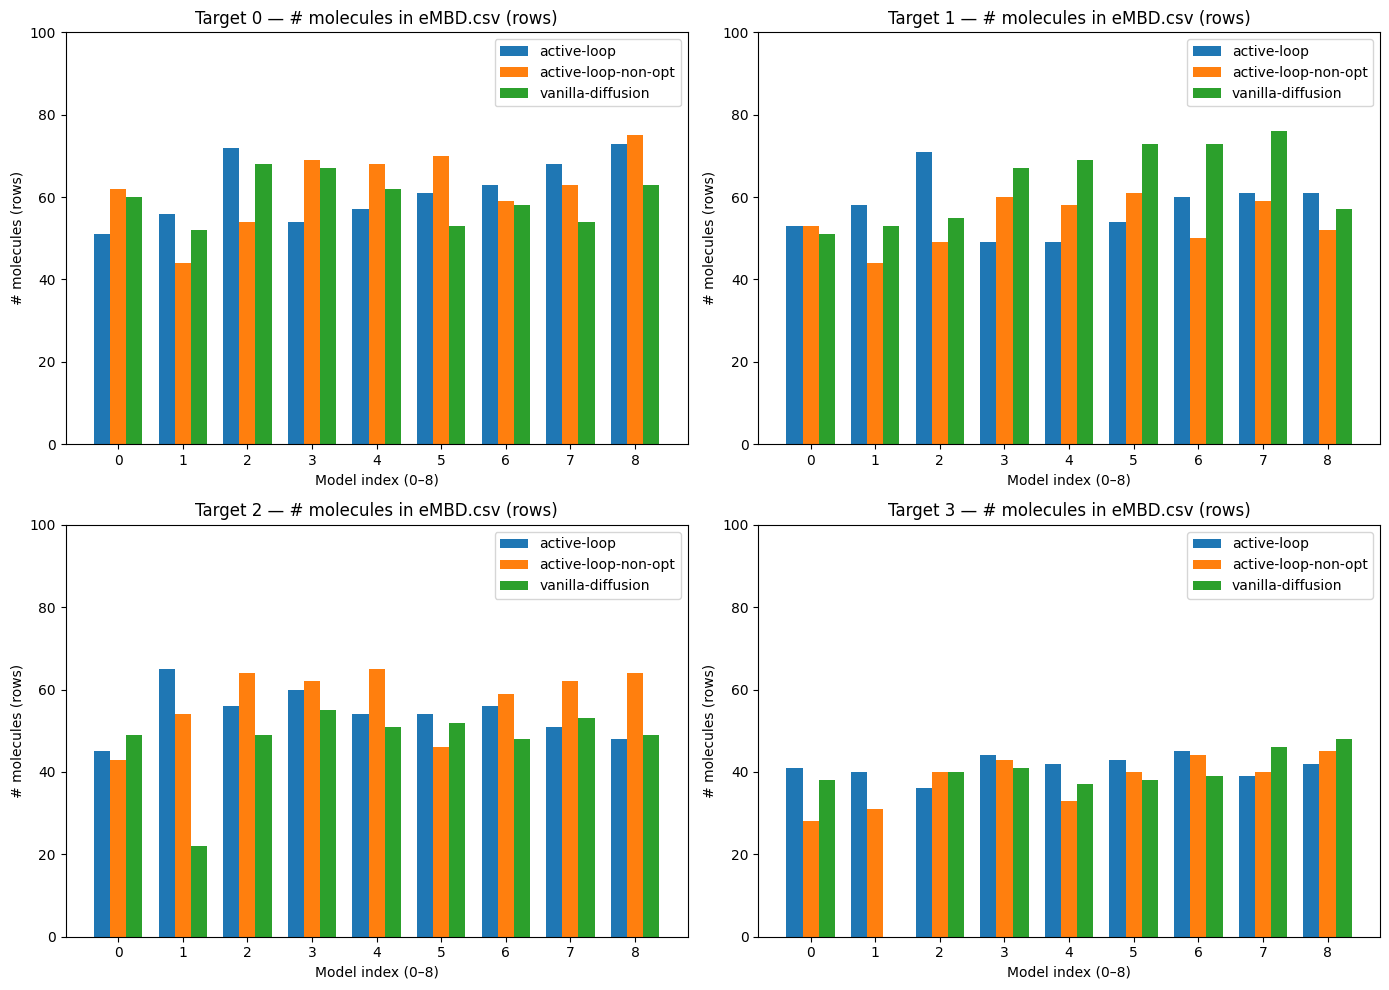

In [22]:
# Revised plotting code that treats empty files as zero molecules
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = Path("/data/horse/ws/miha493e-research_project/activediffusion/data")

folders = {
    "active-loop": "data_embd_jmp",
    "active-loop-non-opt": "data_embd_non_opt",
    "vanilla-diffusion": "data_vanilla"
}

targets = range(4)  # target0..target3 (4 histograms)
models = range(9)   # model0..model8 (9 models on x-axis)
labels = list(folders.keys())

def safe_count_csv_rows(csv_path):
    """
    Return number of rows in CSV. If file missing or empty -> 0.
    If CSV can't be parsed -> 0 and print a warning.
    """
    if not csv_path.exists():
        # missing file -> 0
        return 0
    try:
        # use low_memory=False to avoid dtype warnings; allow any separator (default comma)
        df = pd.read_csv(csv_path, low_memory=False)
        # empty DataFrame -> 0
        return len(df)
    except pd.errors.EmptyDataError:
        # explicitly empty file -> 0
        return 0
    except Exception as e:
        print(f"Warning: couldn't read {csv_path!s}: {e}")
        return 0

def safe_count_sas_tiers(txt_path, tiers_to_count={1,2,3}):
    """
    Read sascore.txt (whitespace or tab-separated), expect at least 3 columns.
    Count rows where third column (tier) is in tiers_to_count.
    If file missing or empty or missing column -> 0.
    """
    if not txt_path.exists():
        return 0
    try:
        # Try reading as whitespace/tab-separated with no header
        # header=None ensures even if there's no header we get columns indexed 0,1,2,...
        df = pd.read_csv(txt_path, sep=r'\s+', header=None, engine='python', comment='#', skip_blank_lines=True)
        if df.shape[0] == 0:
            return 0  # empty after reading
        if df.shape[1] < 3:
            # file present but doesn't have expected 3 columns -> warn and return 0
            print(f"Warning: {txt_path!s} has fewer than 3 columns (has {df.shape[1]}). Counting 0.")
            return 0
        # third column might be numeric or string like 'tier_1' or '1' or 'tier_1,'
        # normalize by extracting digits
        tier_col = df.iloc[:, 2].astype(str).str.extract(r'(\d+)')[0]
        tier_col = pd.to_numeric(tier_col, errors='coerce')  # non-digits -> NaN
        count = tier_col.isin(list(tiers_to_count)).sum()
        return int(count)
    except pd.errors.EmptyDataError:
        return 0
    except Exception as e:
        print(f"Warning: couldn't parse {txt_path!s}: {e}")
        return 0

# ---------- Part 1: eMBD.csv counts ----------
results_embd = {label: [ [0]*len(models) for _ in targets ] for label in labels}

for li, label in enumerate(labels):
    dirname = folders[label]
    for t in targets:
        for m in models:
            csv_path = BASE_DIR / dirname / f"evaluation/target{t}/model{m}/results/eMBD.csv"
            results_embd[label][t][m] = safe_count_csv_rows(csv_path)

# ---------- Plot Part 1 ----------
x = np.arange(len(models))
width = 0.25

fig, axs = plt.subplots(2, 2, figsize=(14, 10))
axs = axs.flatten()
for t in targets:
    ax = axs[t]
    for i, label in enumerate(labels):
        offsets = (i - 1) * width  # center three bars around each x
        ax.bar(x + offsets, results_embd[label][t], width=width, label=label)
    ax.set_title(f"Target {t} — # molecules in eMBD.csv (rows)")
    ax.set_xlabel("Model index (0–8)")
    ax.set_xticks(x)
    ax.set_xticklabels([str(m) for m in models])
    ax.set_ylabel("# molecules (rows)")
    ax.legend()
    ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()



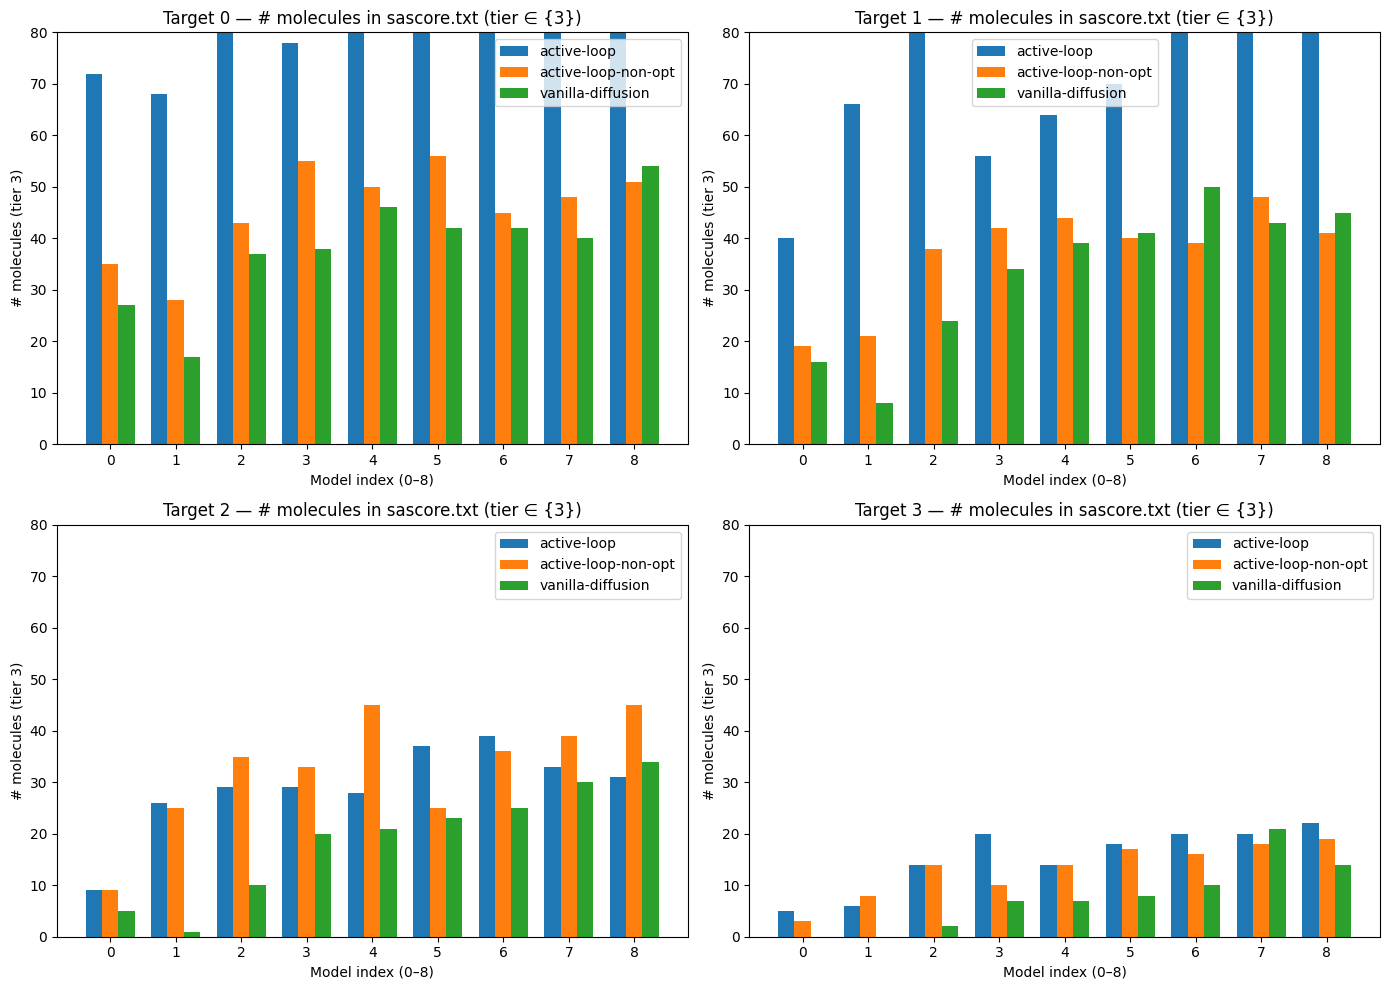

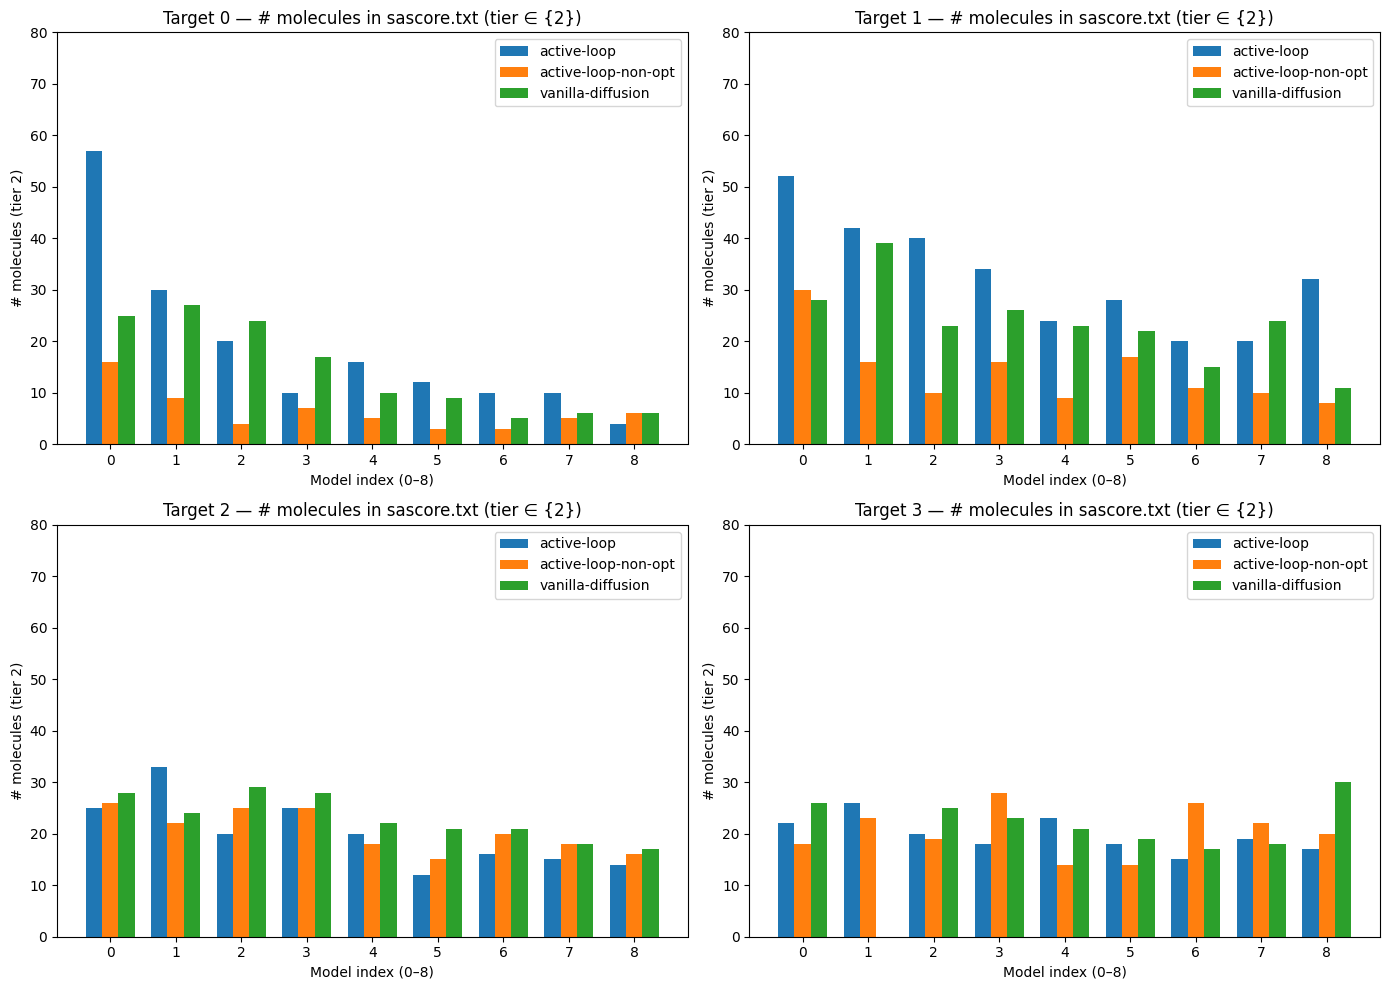

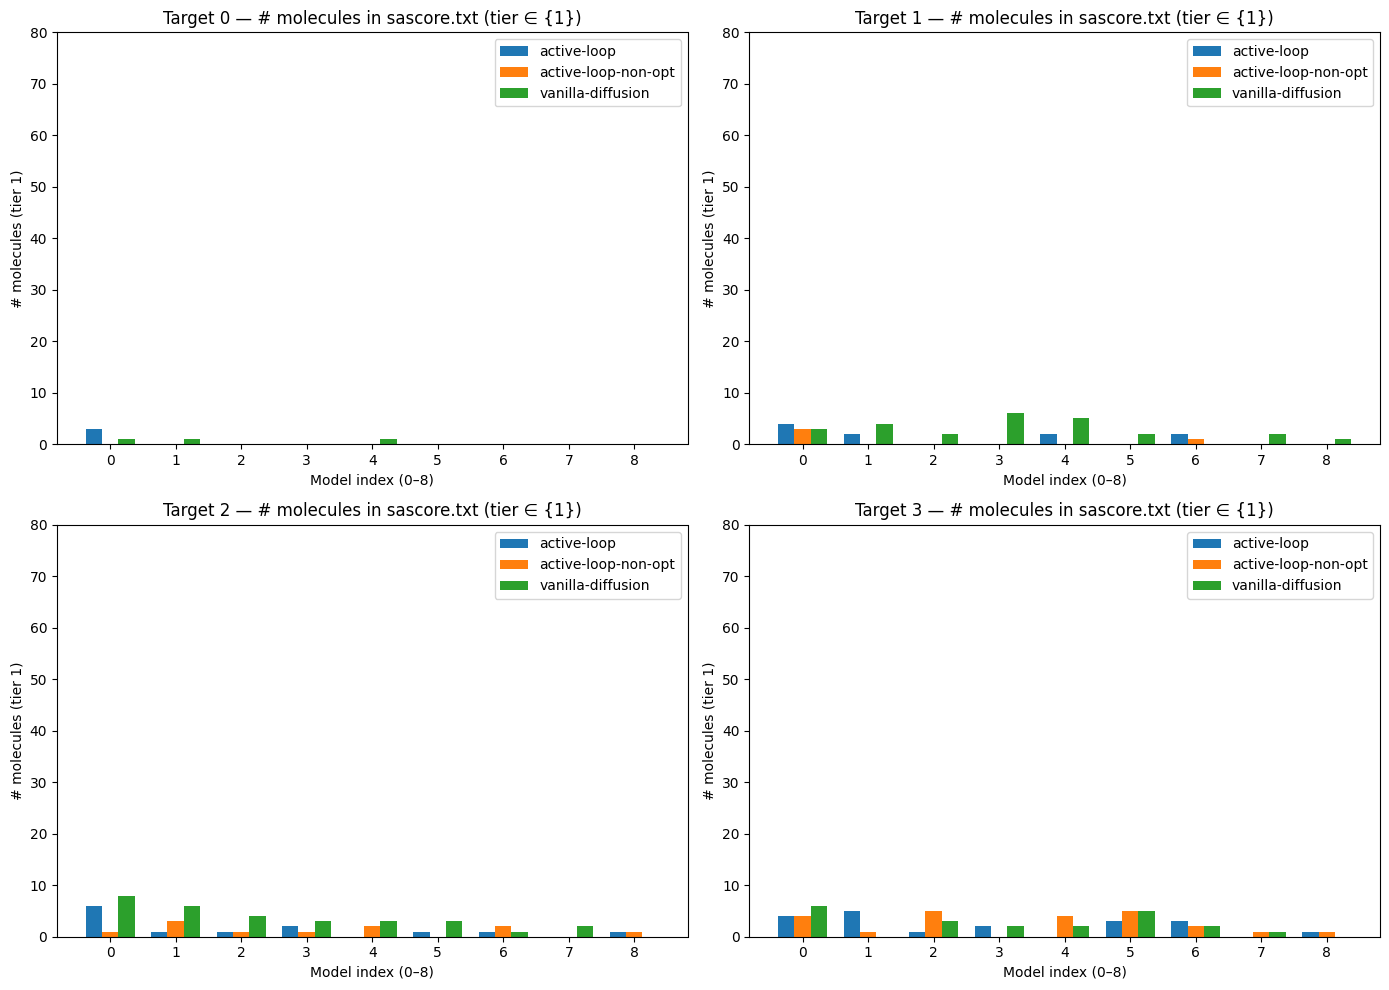

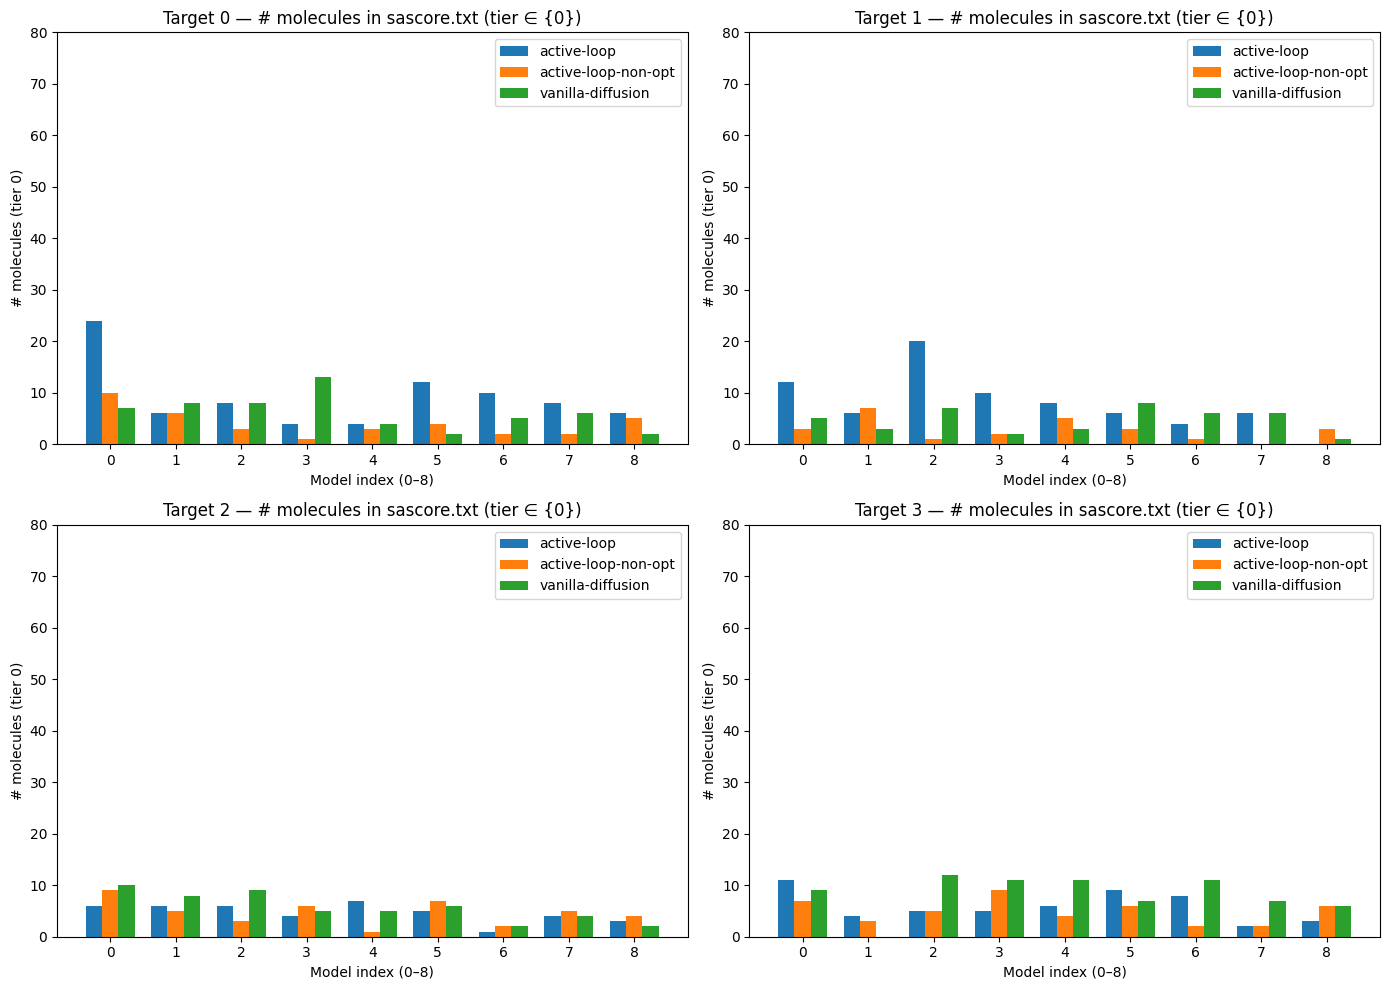

In [23]:
# ---------- Part 2: sascore.txt counts (tiers 3) ----------
results_sas = {label: [ [0]*len(models) for _ in targets ] for label in labels}

for li, label in enumerate(labels):
    dirname = folders[label]
    for t in targets:
        for m in models:
            txt_path = BASE_DIR / dirname / f"evaluation/target{t}/model{m}/results/sascore.txt"
            results_sas[label][t][m] = safe_count_sas_tiers(txt_path, tiers_to_count={3})

# ---------- Plot Part 2 ----------
fig, axs = plt.subplots(2, 2, figsize=(14, 10))
axs = axs.flatten()
for t in targets:
    ax = axs[t]
    for i, label in enumerate(labels):
        offsets = (i - 1) * width
        ax.bar(x + offsets, results_sas[label][t], width=width, label=label)
    ax.set_title(f"Target {t} — # molecules in sascore.txt (tier ∈ {{3}})")
    ax.set_xlabel("Model index (0–8)")
    ax.set_xticks(x)
    ax.set_xticklabels([str(m) for m in models])
    ax.set_ylabel("# molecules (tier 3)")
    ax.legend()
    ax.set_ylim(0, 80)
plt.tight_layout()
plt.show()

# ---------- Part 3: sascore.txt counts (tiers 2) ----------
results_sas = {label: [ [0]*len(models) for _ in targets ] for label in labels}

for li, label in enumerate(labels):
    dirname = folders[label]
    for t in targets:
        for m in models:
            txt_path = BASE_DIR / dirname / f"evaluation/target{t}/model{m}/results/sascore.txt"
            results_sas[label][t][m] = safe_count_sas_tiers(txt_path, tiers_to_count={2})

# ---------- Plot Part 2 ----------
fig, axs = plt.subplots(2, 2, figsize=(14, 10))
axs = axs.flatten()
for t in targets:
    ax = axs[t]
    for i, label in enumerate(labels):
        offsets = (i - 1) * width
        ax.bar(x + offsets, results_sas[label][t], width=width, label=label)
    ax.set_title(f"Target {t} — # molecules in sascore.txt (tier ∈ {{2}})")
    ax.set_xlabel("Model index (0–8)")
    ax.set_xticks(x)
    ax.set_xticklabels([str(m) for m in models])
    ax.set_ylabel("# molecules (tier 2)")
    ax.legend()
    ax.set_ylim(0, 80)
plt.tight_layout()
plt.show()


# ---------- Part 4: sascore.txt counts (tiers 1) ----------
results_sas = {label: [ [0]*len(models) for _ in targets ] for label in labels}

for li, label in enumerate(labels):
    dirname = folders[label]
    for t in targets:
        for m in models:
            txt_path = BASE_DIR / dirname / f"evaluation/target{t}/model{m}/results/sascore.txt"
            results_sas[label][t][m] = safe_count_sas_tiers(txt_path, tiers_to_count={1})

# ---------- Plot Part 4 ----------
fig, axs = plt.subplots(2, 2, figsize=(14, 10))
axs = axs.flatten()
for t in targets:
    ax = axs[t]
    for i, label in enumerate(labels):
        offsets = (i - 1) * width
        ax.bar(x + offsets, results_sas[label][t], width=width, label=label)
    ax.set_title(f"Target {t} — # molecules in sascore.txt (tier ∈ {{1}})")
    ax.set_xlabel("Model index (0–8)")
    ax.set_xticks(x)
    ax.set_xticklabels([str(m) for m in models])
    ax.set_ylabel("# molecules (tier 1)")
    ax.legend()
    ax.set_ylim(0, 80)
plt.tight_layout()
plt.show()

# ---------- Part 5: sascore.txt counts (tiers 0) ----------
results_sas = {label: [ [0]*len(models) for _ in targets ] for label in labels}

for li, label in enumerate(labels):
    dirname = folders[label]
    for t in targets:
        for m in models:
            txt_path = BASE_DIR / dirname / f"evaluation/target{t}/model{m}/results/sascore.txt"
            results_sas[label][t][m] = safe_count_sas_tiers(txt_path, tiers_to_count={0})

# ---------- Plot Part 5 ----------
fig, axs = plt.subplots(2, 2, figsize=(14, 10))
axs = axs.flatten()
for t in targets:
    ax = axs[t]
    for i, label in enumerate(labels):
        offsets = (i - 1) * width
        ax.bar(x + offsets, results_sas[label][t], width=width, label=label)
    ax.set_title(f"Target {t} — # molecules in sascore.txt (tier ∈ {{0}})")
    ax.set_xlabel("Model index (0–8)")
    ax.set_xticks(x)
    ax.set_xticklabels([str(m) for m in models])
    ax.set_ylabel("# molecules (tier 0)")
    ax.legend()
    ax.set_ylim(0, 80)
plt.tight_layout()
plt.show()



In [36]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path



# ---------------------------------------------------------
# Safe CSV reader (handles empty or missing files)
# ---------------------------------------------------------
def safe_read_csv(path):
    if not path.exists() or path.stat().st_size == 0:
        return None
    try:
        df = pd.read_csv(path, header=None)
        if df.empty:
            return None
        return df
    except:
        return None

# ---------------------------------------------------------
# Count tier_3 molecules with |relative error| ≤ 5%
# ---------------------------------------------------------
def compute_valid_molecules(path_embd, path_sas):
    df_embd = safe_read_csv(path_embd)
    df_sas = safe_read_csv(path_sas)

    if df_embd is None or df_sas is None:
        return 0  # One file empty → no match possible

    # Extract columns by your correct structure (0-based indexing)
    # eMBD.csv
    embd_names = df_embd.iloc[:, 0].astype(str)
    col2 = pd.to_numeric(df_embd.iloc[:, 2], errors="coerce")
    col3 = pd.to_numeric(df_embd.iloc[:, 3], errors="coerce")

    # relative error
    rel_err = (col3 / col2) * 100
    df_embd_clean = pd.DataFrame({
        "name": embd_names,
        "rel_err": rel_err
    }).dropna()

    # sascore
    sas_names = df_sas.iloc[:, 0].astype(str)
    sas_tier = df_sas.iloc[:, 2].astype(str)
    df_sas_clean = pd.DataFrame({
        "name": sas_names,
        "tier": sas_tier
    })

    # merge on molecule name (inner: only those in both)
    merged = df_embd_clean.merge(df_sas_clean, on="name", how="inner")

    # keep tier_3
    merged = merged[merged["tier"] == "tier_3"]

    # keep |relative error| ≤ 5
    merged = merged[merged["rel_err"].abs() <= 5]

    return len(merged)


# ---------------------------------------------------------
# MAIN LOOP
# ---------------------------------------------------------
experiments = ["data_embd_jmp", "data_embd_non_opt", "data_vanilla"]
targets = [0, 1, 2, 3] 
models = range(8)

results = {exp: {t: {m: 0 for m in models} for t in targets} for exp in experiments}

for exp in experiments:
    for t in targets:
        for m in models:
            embd_path = BASE_DIR / exp / f"evaluation/target{t}/model{m}/results/eMBD.csv"
            sas_path = BASE_DIR / exp / f"evaluation/target{t}/model{m}/results/sascore.txt"

            results[exp][t][m] = compute_valid_molecules(embd_path, sas_path)

# ---------------------------------------------------------
# PLOTTING
# ---------------------------------------------------------
for t in targets:
    plt.figure(figsize=(12, 6))
    for exp in experiments:
        y = [results[exp][t][m] for m in models]
        plt.plot(models, y, label=exp, marker='o')

    plt.title(f"Target {t}: Tier_3 + |Relative Error| ≤ 5%")
    plt.xlabel("Model")
    plt.ylabel("Number of valid molecules")
    plt.ylim(0, 50)   # <-- FIXED MAX Y AXIS (CHANGE IF NEEDED)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()


IndexError: single positional indexer is out-of-bounds

## frequencies

In [144]:
# ----------------------------
# Safe file reading
# ----------------------------
def safe_read(path, sep=r"\s+"):
    if not path.exists() or path.stat().st_size == 0:
        return None
    try:
        df = pd.read_csv(path, header=None, sep=sep, engine='python')
        return None if df.empty else df
    except Exception:
        return None


# ----------------------------
# Compute top-40 stats cleanly
# ----------------------------
def compute_top40_stats(path_embd, path_sas, REL_ERR_THRESHOLD, TIER_ACCEPT, top_k=40):
    df_embd = safe_read(path_embd)
    df_sas = safe_read(path_sas)

    # missing eMBD means nothing to compute
    if df_embd is None or df_embd.shape[1] < 3:
        return 0, 0, 0

    # ---- Clean eMBD ----
    names = df_embd.iloc[:, 0].astype(str).str.strip().str.replace(r"\s+", "", regex=True)
    pred = pd.to_numeric(df_embd.iloc[:, 1], errors="coerce")
    ref  = pd.to_numeric(df_embd.iloc[:, 2], errors="coerce")

    rel_err = ((pred - ref).abs() / ref.abs() * 100).replace([float('inf'), -float('inf')], pd.NA)

    df = pd.DataFrame({"name": names, "rel_err": rel_err}).dropna()

    # ---- Step 1: pick top-40 lowest abs(relative error) ----
    df_top40 = df.loc[df["rel_err"].abs().sort_values().index].head(top_k)
    top40_names = set(df_top40["name"].values)

    # ---- Step 2: accuracy <= REL_ERR_THRESHOLD ----
    df_acc = df_top40[df_top40["rel_err"] <= REL_ERR_THRESHOLD]
    acc_names = set(df_acc["name"].values)

    # No sascore → no tier count
    if df_sas is None or df_sas.shape[1] < 3:
        return len(df_top40), len(df_acc), 0

    # ---- Clean & deduplicate SAS ----
    sas_names = df_sas.iloc[:, 0].astype(str).str.strip().str.replace(r"\s+", "", regex=True)
    sas_tier  = df_sas.iloc[:, 2].astype(str)

    df_sas_clean = pd.DataFrame({"name": sas_names, "tier": sas_tier})

    # IMPORTANT FIX: ensure 1 row per molecule
    df_sas_clean = df_sas_clean.drop_duplicates(subset=["name"])

    # ---- Step 3: keep only accurate top-40 molecules ----
    df_acc_tiers = df_sas_clean[df_sas_clean["name"].isin(acc_names)]

    # ---- Step 4: filter tiers ----
    df_final = df_acc_tiers[df_acc_tiers["tier"].isin(TIER_ACCEPT)]

    return len(df_top40), len(df_acc), len(df_final)


In [149]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ----------------------------
# User settings
# ----------------------------
BASE_DIR = Path("/data/horse/ws/miha493e-research_project/activediffusion/data")  # main data directory
experiments = ["data_embd_jmp", "data_embd_non_opt", "data_vanilla"]
exp_labels = ["active-loop", "active-loop-non-opt", "vanilla-diffusion"]
targets = [0, 1, 2, 3]
models = range(9)  # 0–7
REL_ERR_THRESHOLD = 5  # +/-5%
TIER_ACCEPT_G = ["tier_2", "tier_3"]  # tiers to include
TIER_ACCEPT_B = ["tier_0", "tier_1"]



# ----------------------------
# Compute results
# ----------------------------
# results = {label: {t: [0]*len(models) for t in targets} for label in exp_labels}
results_top40_g = {label: {t: [0]*len(models) for t in targets} for label in exp_labels}
results_ac_g   = {label: {t: [0]*len(models) for t in targets} for label in exp_labels}
results_final_g  = {label: {t: [0]*len(models) for t in targets} for label in exp_labels}
results_top40_b = {label: {t: [0]*len(models) for t in targets} for label in exp_labels}
results_acc_b   = {label: {t: [0]*len(models) for t in targets} for label in exp_labels}
results_final_b  = {label: {t: [0]*len(models) for t in targets} for label in exp_labels}

for exp, label in zip(experiments, exp_labels):
    for t in targets:
        for m in models:
            path_embd = BASE_DIR / exp / f"evaluation/target{t}/model{m}/results/eMBD.csv"
            path_sas = BASE_DIR / exp / f"evaluation/target{t}/model{m}/results/sascore.txt"
            # count = compute_valid_molecules(path_embd, path_sas)
            # results[label][t][m] = count
            top40_count_g, acc_count_g, final_count_g = compute_top40_stats(path_embd, path_sas, REL_ERR_THRESHOLD, TIER_ACCEPT_G)
            results_top40_g[label][t][m] = top40_count_g
            results_ac_g[label][t][m]   = acc_count_g
            results_final_g[label][t][m]  = final_count_g
            top40_count_b, acc_count_b, final_count_b = compute_top40_stats(path_embd, path_sas, REL_ERR_THRESHOLD, TIER_ACCEPT_B)
            results_top40_b[label][t][m] = top40_count_b
            results_acc_b[label][t][m]   = acc_count_b
            results_final_b[label][t][m]  = final_count_b
            # print(f"{label} target{t} model{m} → {final_count} molecules")  # optional debug


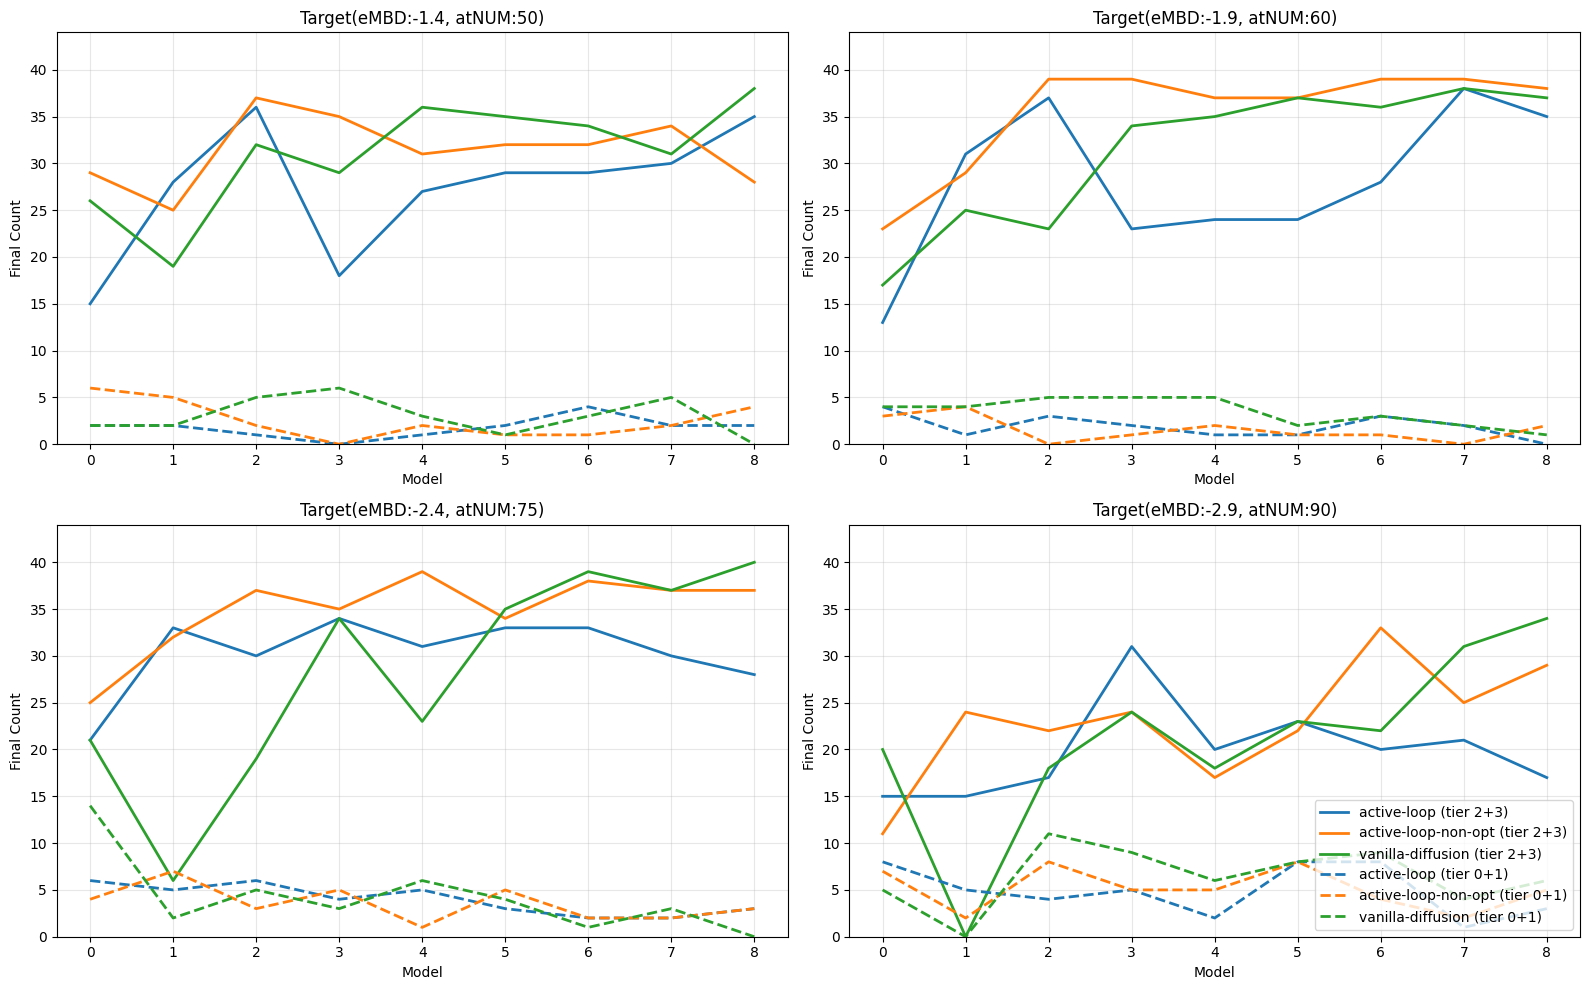

In [150]:
x = list(models)                          # x-axis = models
colors = ["tab:blue", "tab:orange", "tab:green"]  # for 3 experiments
linestyles = ["-", "-.", ":"]             # different for G/B per experiment

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()
target_names = ["Target(eMBD:-1.4, atNUM:50)" , "Target(eMBD:-1.9, atNUM:60)", "Target(eMBD:-2.4, atNUM:75)", "Target(eMBD:-2.9, atNUM:90)"]
for idx, t in enumerate(targets):
    ax = axes[idx]

    # Compute max_y for clean scaling
    max_y = 0
    for label in exp_labels:
        max_y = 40

    # ---- Plot G (tier_2 + tier_3) ----
    for i, label in enumerate(exp_labels):
        y_g = results_final_g[label][t]  # list of len(models)
        ax.plot(
            x, y_g,
            color=colors[i],
            linestyle="-",
            linewidth=2,
            label=f"{label} (tier 2+3)"
        )

    # ---- Plot B (tier_0 + tier_1) ----
    
    for i, label in enumerate(exp_labels):
        y_b = results_final_b[label][t]
        ax.plot(
            x, y_b,
            color=colors[i],
            linestyle="--",
            linewidth=2,
            label=f"{label} (tier 0+1)"
        )

    ax.set_title(target_names[t])
    ax.set_xlabel("Model")
    ax.set_ylabel("Final Count")
    ax.set_xticks(x)
    ax.set_ylim(0, max_y * 1.1)
    ax.grid(True, alpha=0.3)
    
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()


## new reading

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from matplotlib.lines import Line2D

top = True  # True = lowest abs rel error, False = highest
n = 20      # number of molecules to sample per model

base_path = "/data/horse/ws/miha493e-research_project/activediffusion/data/"
experiments = ["data_full_dataset", "data_vanilla"]

columns = ["molecule_name", "calculated_property", "reference_property", "error", "calRelError"]

fig, axes = plt.subplots(2, 1, figsize=(16, 12), sharey=True)
axes = axes.flatten()


# Custom legend for tiers (dots)
tier_handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='red', markersize=8, label='tier 0/1'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='black', markersize=8, label='tier 2'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='green', markersize=8, label='tier 3')
]

# Add target legend if needed (from violinplot hue)
target_palette = sns.color_palette("Set2", 4)
target_labels = ["target0", "target1", "target2", "target3"]
target_handles = [
    Line2D([0], [0], marker='s', color='w', markerfacecolor=target_palette[i], markersize=10, label=target_labels[i])
    for i in range(4)
]


for exp_idx, exp in enumerate(experiments):
    exp_path = os.path.join(base_path, exp)
    data = []

    target_folders = [
        (exp_path+"/evaluation/target0", "target0"),
        (exp_path+"/evaluation/target1", "target1"),
        (exp_path+"/evaluation/target2", "target2"),
        (exp_path+"/evaluation/target3", "target3")
    ]

    for folder, target_name in target_folders:
        for model_name in os.listdir(folder):
            model_path = os.path.join(folder, model_name)
            if not os.path.isdir(model_path):
                continue

            csv_path = os.path.join(model_path, "results/eMBD.csv")
            if not os.path.exists(csv_path):
                continue

            df = pd.read_csv(csv_path, header=None, names=columns, sep='\t')
            df["model"] = model_name
            df["target"] = target_name
            df = df.drop_duplicates(subset="molecule_name", keep="first")
            df["relative_error"] = 100*((df["calculated_property"] - df["reference_property"]) / df["reference_property"])

            df_top40 = df.loc[df["relative_error"].abs().sort_values(ascending=top).index].head(n)

            # Read sascore.txt
            sas_path = os.path.join(model_path, "results/sascore.txt")
            if os.path.exists(sas_path):
                df_sas = pd.read_csv(sas_path, header=None, sep=r"\s+")
                df_sas = df_sas[[0,2]]
                df_sas.columns = ["molecule_name", "tier"]
                df_sas["molecule_name"] = df_sas["molecule_name"].astype(str).str.strip()
                df_sas["tier"] = df_sas["tier"].astype(str).str.strip()
            else:
                df_sas = pd.DataFrame(columns=["molecule_name", "tier"])

            df_top40 = df_top40.merge(df_sas, on="molecule_name", how="left")

            def tier_to_color(t):
                if t in ["tier_0", "tier_1"]:
                    return "red"
                elif t == "tier_2":
                    return "black"
                else:
                    return "green"

            df_top40["tier_color"] = df_top40["tier"].apply(tier_to_color)
            data.append(df_top40)

    df_all = pd.concat(data, ignore_index=True)
    df_all["model"] = pd.Categorical(df_all["model"], categories=sorted(df_all["model"].unique()), ordered=True)

    ax = axes[exp_idx]

    sns.violinplot(data=df_all, x="model", y="relative_error", hue="target", palette="Set2", split=True, ax=ax, inner="quartile")

    sns.stripplot(data=df_all, x="model", y="relative_error",
                  hue="tier_color", palette={"red":"red", "black":"black", "green":"green"},
                  dodge=False, size=4, jitter=True, marker="o", alpha=0.8, ax=ax)

    ax.axhline(0, color='red', linestyle='--')
    ax.axhline(5, color='blue', linestyle='--')
    ax.axhline(-5, color='blue', linestyle='--')

    ax.set_title(exp)
    ax.set_xlabel("Model")
    if exp_idx == 0:
        ax.set_ylabel("Relative Error (%)")
    ax.tick_params(axis='x', rotation=45)
    ax.legend_.remove()

# Combine and set legend
plt.legend(handles=target_handles + tier_handles , loc="lower right")

plt.tight_layout()
plt.show()


: 